In [19]:
import numpy as np
import pandas as pd
from numpy.random import binomial
from scipy.stats import binom
from math import factorial
import matplotlib.pyplot as plt

In [ ]:
#DISTRIBUCIONES DISCRETAS: DISTRIBUCION BINOMIAL

def my_binomial (k,n,p):
    return factorial(n)/ factorial(k)*factorial(n-k)*pow(p,k)*pow(1-p,n-k)

resultado= my_binomial(2,3,0.5)
print(f"La probabilidad de lanzar obtener 2 caras al lanzar 3 monedas es {resultado}")

dist= binom(3, 0.5)
dist= dist.pmf(2) #Densidad de probabilidad
print(f"La probabilidad de lanzar obtener 2 caras al lanzar 3 monedas es {dist}")

La probabilidad de lanzar obtener 2 caras al lanzar 3 monedas es 0.375
La probabilidad de lanzar obtener 2 caras al lanzar 3 monedas es 0.3750000000000001


In [ ]:
dist= binom(3, 0.5)
dist.cdf(2) #Distribucion de probabilidad acumulada

0.875

In [ ]:
#GENERADORES ALEATORIOS

p= 0.5 #probabilidad
n= 3 #numero de lanzamientos de la moneda
caras= binomial(n,p)
#print(f"Se lanzaron 3 monedas y salieron {caras} caras") 

arr= [] 
for i in range(100):
    arr.append(binomial(n,p))
#print(arr)

def plot_hist(num_trials):
    values= [0,1,2,3]
    arr= []
    for i in range(num_trials):
        arr.append(binomial(n,p))

unique= np.unique(arr, return_counts= True) #listar los elementos unicos de una lista
unique[1]/len(arr) #Obtener las probabilidades de los lanzamientos... 
#...se pone 1 porque arr es una lista de listas, donde la segunda posicion contiene los resultados de los lanzamientos


array([0.09, 0.39, 0.44, 0.08])

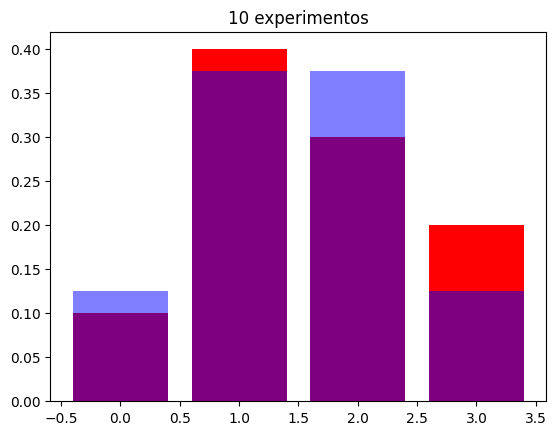

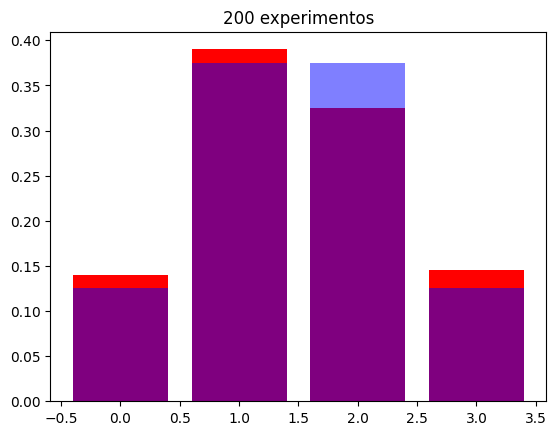

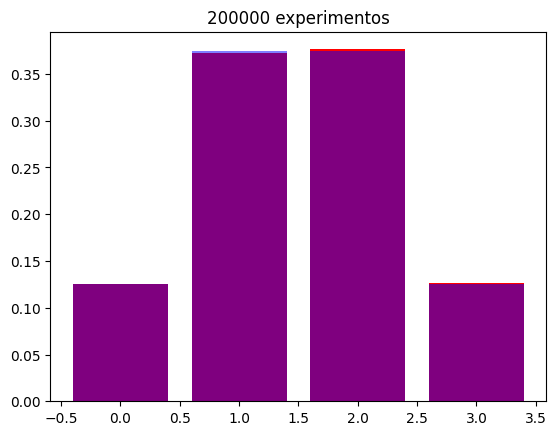

In [ ]:
p= 0.5 #probabilidad
n= 3 #numero de lanzamientos de la moneda
caras= binomial(n,p)

def plot_hist(num_trials):
    values= [0,1,2,3]
    arr= []
    for i in range(num_trials):
        arr.append(binomial(n,p))
    simulation= np.unique(arr, return_counts= True)[1]/len(arr) #Es lo mismo que la variable "unico"
    theory = [binom(3, 0.5).pmf(k) for k in values]  #Generar los valores teoricos
    plt.bar(values, simulation, color= "red")
    plt.bar(values, theory, alpha=0.5, color= "blue")
    plt.title(f"{num_trials} experimentos")
    plt.show()

plot_hist(10)
plot_hist(200)
plot_hist(200000)

In [1]:
#DISTRIBUCIONES CONTINUAS: DISTRIBUCION NORMAL

import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from scipy.stats import norm

In [5]:
def gausian (x, mu, sigma):
    return 1/(sigma*np.sqrt(2*np.pi))*np.exp(-0.5*pow((x-mu)/sigma,2))

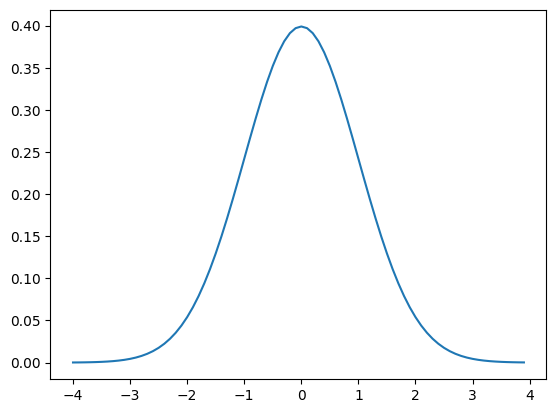

In [7]:
x= np.arange(-4,4,0.1)
y= gausian(x,0,1)

plt.plot(x,y)

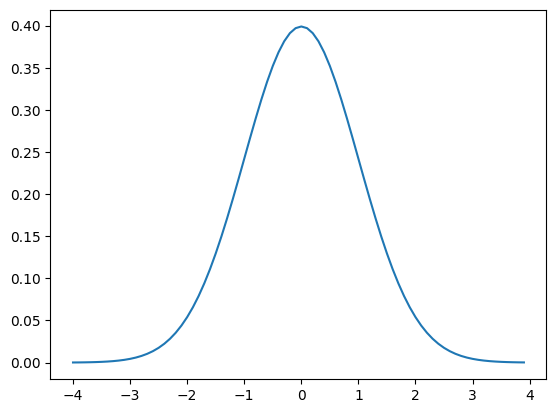

In [11]:
#Usando Scipy

dist= norm(0,1)
x= np.arange(-4,4,0.1)
y= []
for value in x:
    y.append(dist.pdf(value))
#y= [dist.pdf(value) for value in x] #otro metodo mas corto
    
plt.plot(x,y)

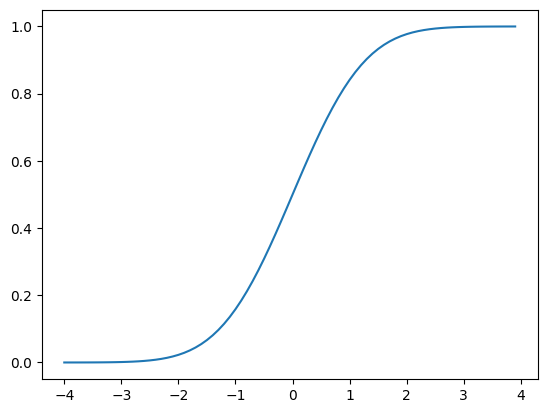

In [16]:
#Calculando la distribucion acumulada

dist= norm(0,1)
x= np.arange(-4,4,0.1)
y= []
for value in x:
    y.append(dist.cdf(value))
plt.plot(x,y)

<BarContainer object of 20 artists>

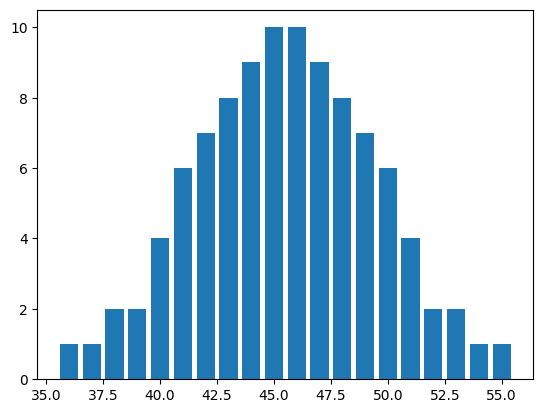

In [28]:
import os
import pandas as pd

os.chdir("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/estadistica_descriptiva/")

df= pd.read_excel("wings.xls")
arr= df["Normally Distributed Housefly Wing Lengths"].values[3:]
values, dist = np.unique(arr, return_counts= True)
plt.bar(values, dist)

<BarContainer object of 20 artists>

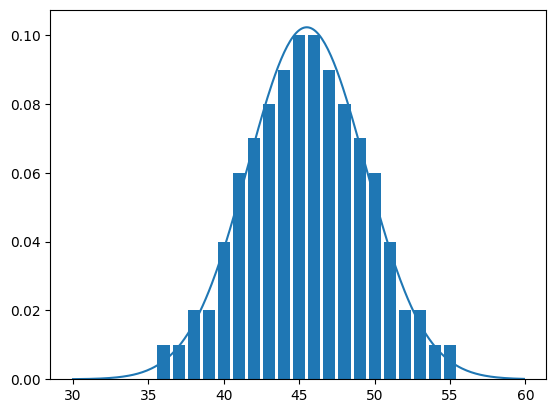

In [36]:
#Estimacion de la distribucion de probabilidad

mu= arr.mean()
sigma= arr.std()

dist= norm(mu, sigma)

x= np.arange(30,60,0.1)
y= []
for value in x:
    y.append(dist.pdf(value))
plt.plot(x,y)

#datos
values, dist= np.unique(arr, return_counts= True)
plt.bar(values, dist/len(arr))



In [37]:
#ESTIMAR UNA DISTRIBUCION

import numpy as np
from matplotlib import pyplot 
from numpy.random import normal
from scipy.stats import norm

(array([1.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 4.000e+00, 1.300e+01,
        2.300e+01, 5.000e+01, 1.160e+02, 1.930e+02, 2.750e+02, 4.710e+02,
        5.720e+02, 8.090e+02, 9.870e+02, 1.051e+03, 1.090e+03, 1.079e+03,
        9.290e+02, 7.660e+02, 5.700e+02, 4.340e+02, 2.400e+02, 1.540e+02,
        8.600e+01, 4.800e+01, 2.100e+01, 1.200e+01, 4.000e+00, 1.000e+00]),
 array([-4.6075276 , -4.32558873, -4.04364986, -3.76171099, -3.47977212,
        -3.19783325, -2.91589438, -2.63395551, -2.35201664, -2.07007777,
        -1.7881389 , -1.50620003, -1.22426116, -0.94232229, -0.66038342,
        -0.37844455, -0.09650568,  0.18543319,  0.46737206,  0.74931093,
         1.0312498 ,  1.31318867,  1.59512754,  1.87706641,  2.15900528,
         2.44094415,  2.72288302,  3.00482189,  3.28676076,  3.56869963,
         3.8506385 ]),
 <BarContainer object of 30 artists>)

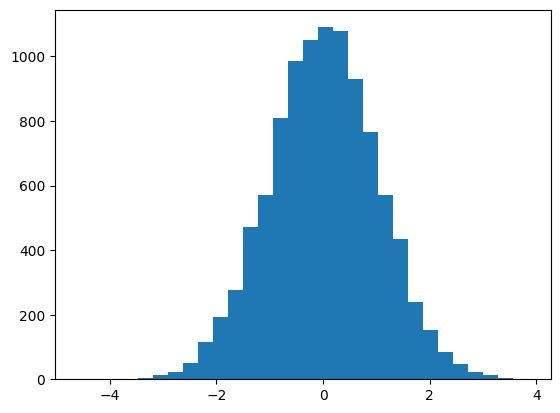

In [41]:
sample= normal(size= 10000)
plt.hist(sample, bins= 30)

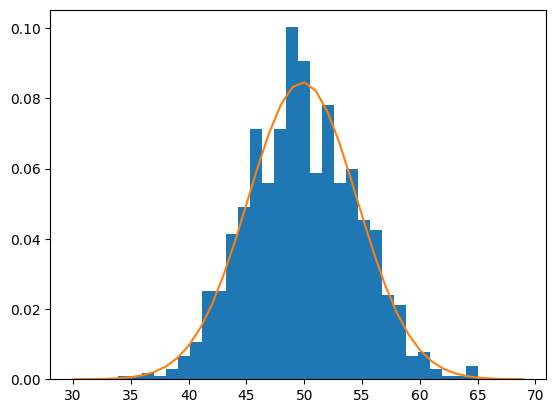

In [44]:
#Estimacion parametrica
sample= normal(loc= 50, scale= 5, size= 1000) # mu = 50, sigma = 5
mu= sample.mean()
sigma= sample.std()
dist= norm(mu, sigma)

values = []
for value in range(30,70):
    values.append(value)
#values = [value for value in range(30, 70)] Es lo mismo que el ciclo for de arriba

probabilities = []
for value in values:
    probabilities.append(dist.pdf(value))

plt.hist(sample, bins= 30, density= True)
plt.plot(values, probabilities)


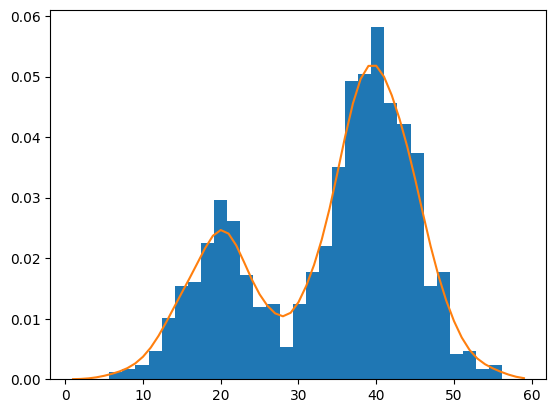

In [60]:
#Estimacion No parametrica

from numpy import hstack
from sklearn.neighbors import KernelDensity

#Construir una distribucion bimodal
sample1= normal(loc= 20, scale= 5, size= 300)
sample2= normal(loc=40, scale=5, size= 700)
sample= hstack((sample1, sample2))

model= KernelDensity(bandwidth=2, kernel= "gaussian")
sample= sample.reshape(len(sample),1)
model.fit(sample)

values = np.asarray([])
for value in range(1, 60):
    values= np.append(values, value)
    
values= values.reshape(len(values),1)
probabilities = model.score_samples(values) #probabilidad logaritmica
probabilities = np.exp(probabilities) #inversion de probabilidad

plt.hist(sample, bins= 30, density=True)
plt.plot(values[:], probabilities)